In [198]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns                      # a library on top of matplotlib: nicer defaults with less code
from scipy import stats                    # t-test
import statsmodels.formula.api as smf      # regression with a full results table
import wrds
from statsmodels.iolib.summary2 import summary_col

conn = wrds.Connection()

SIC        = "58"
FY_START   = "2021-01-01"     # we study fiscal years that END between FY_START and FY_END
FY_END     = "2024-12-31"
PULL_START = "2019-06-01"     # we pull earlier years too, because the EPS change needs last year's EPS and price
RET_START  = "2020-12-01"     # first month of returns (12 months before the first fiscal year-end)
RET_END    = "2025-01-31"     # last month of returns
MIN_PRC    = 5                # rule: drop a company-year if last year's price is below this
MAX_CHG    = 1                # rule: drop a company-year if the EPS change is bigger than this (up or down)

Loading library list...
Done


In [199]:
# ===== Step 1. Read the link file =====

# 1a. Read every column as text, so that nothing is changed or guessed at this point.
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# 1b. gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# 1c. permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# 1d. The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
# format="mixed" accepts different date formats. errors="coerce" turns a bad value into a missing date.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# 1e. A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# 1f. Keep only the companies in our industry.
link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)
if len(link) == 0:
    raise ValueError("SIC " + SIC + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows:", len(link), "| companies:", link["gvkey"].nunique())
link.head()

link rows: 42 | companies: 36


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,003007,23297,1984-01-06,2099-12-31,58,EAT,BRINKER INTERNATIONAL INC
1,003369,79618,1993-09-01,2099-12-31,58,RAVE,RAVE RESTAURANT GROUP INC
2,003570,27562,1981-11-05,2099-12-31,58,CBRL,CRACKER BARREL OLD COUNTRY STORE
3,003708,19828,1950-01-01,1962-01-30,58,WEN,WENDYS CO
4,003708,19828,1962-01-31,1967-11-05,58,WEN,WENDYS CO


In [200]:
# ===== Step 2. Pull the quarterly data =====
# 2a. The SQL query needs the gvkeys as one text:  '001690','002176',...
gv = "'" + "','".join(link["gvkey"].unique()) + "'"

# 2b. Ask WRDS for only the rows and columns we need.
fa = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, epspxq, prccq, rdq, fqtr
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate"])

# 2c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (a missing value becomes NaN).
fa["epspxq"]  = fa["epspxq"].astype("float64")
fa["prccq"] = fa["prccq"].astype("float64")
fa["fyearq"] = fa["fyearq"].astype(int)
fa["fqtr"] = fa["fqtr"].astype(int)

# 2d. Check what we got.
print("company-years pulled from Compustat:", len(fa))
fa

company-years pulled from Compustat: 771


,gvkey,datadate,fyearq,epspxq,prccq,rdq,fqtr
0,003007,2019-06-30,2019,1.25,39.35,2019-08-13,4
1,003369,2019-06-30,2019,-0.06,3.08,2019-09-30,4
2,003708,2019-06-30,2019,0.14,19.58,2019-08-07,2
3,004759,2019-06-30,2019,0.52,23.00,2019-08-13,3
4,007154,2019-06-30,2019,1.99,207.66,2019-07-26,2
...,...,...,...,...,...,...,...
766,065417,2024-12-31,2024,1.51,134.16,2025-02-06,4
767,148470,2024-12-31,2024,-2.48,5.49,2025-02-26,4
768,160376,2024-12-31,2024,1.74,180.43,2025-02-20,4
769,165914,2024-12-31,2024,0.24,60.30,2025-02-04,4


In [201]:
# ===== Step 3a. Merge 1: add permno from the link file =====
panel = fa.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
print("3a. after the merge (a gvkey with 2 links is now on 2 rows):", len(panel))

3a. after the merge (a gvkey with 2 links is now on 2 rows): 908


In [202]:
# ===== Step 3b. Keep only the link that was valid on the fiscal year-end date =====

# True/False for each row: the date is between the start and the end of the link.
valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
panel = panel[valid]

# How many rows share the same gvkey + fyear with another row?
n_dup = panel.duplicated(["gvkey", "datadate"]).sum()
print("3b. rows that repeat a gvkey + datadate before we drop them:", n_dup)

# If one company-year still has two rows, keep one.
panel = panel.drop_duplicates(["gvkey", "datadate"])

# We do not need the link dates any more.
panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

# Count (used in the sample construction table in Step 6).
r1, c1 = len(fa), fa["gvkey"].nunique()          # before the link
r2, c2 = len(panel), panel["gvkey"].nunique()    # after the link
print("3b. company-years after the link merge:", r2)

3b. rows that repeat a gvkey + datadate before we drop them: 0
3b. company-years after the link merge: 752


In [203]:
# ===== Check: does any key (gvkey + datadate) appear more than once? =====
# duplicated() marks a row True if an earlier row has the same gvkey and fyear. sum() counts the True values.
print("duplicate keys:", panel.duplicated(["gvkey", "datadate"]).sum(), "(it must be 0)")

duplicate keys: 0 (it must be 0)


In [204]:
# ===== Step 3c. Give every quarter a number: =====
q = panel.copy()
q["qnum"] = q["fyearq"] * 4 + q["fqtr"]

In [205]:
# ===== Step 3d. Copy for "EPS four quarters ago": =====
eps4 = q[["gvkey", "qnum", "epspxq"]].copy()
eps4["qnum"] = eps4["qnum"] + 4
eps4 = eps4.rename(columns={"epspxq": "eps_4q_ago"})

In [206]:
# ===== Step 3e. Copy for "price one quarter ago": moved forward by 1=====
prc1 = q[["gvkey", "qnum", "prccq"]].copy()
prc1["qnum"] = prc1["qnum"] + 1
prc1 = prc1.rename(columns={"prccq": "prc_1q_ago"})

In [207]:
# Merge both copies back
q = q.merge(eps4, on=["gvkey", "qnum"], how="left")
q = q.merge(prc1, on=["gvkey", "qnum"], how="left")

In [208]:
# SUE = (EPS this quarter - EPS four quarters ago) / price one quarter ago
q["sue"] = (q["epspxq"] - q["eps_4q_ago"]) / q["prc_1q_ago"]
q[["gvkey", "fyearq", "fqtr", "qnum", "epspxq", "eps_4q_ago", "prc_1q_ago", "sue"]]

,gvkey,fyearq,fqtr,qnum,epspxq,eps_4q_ago,prc_1q_ago,sue
0,003007,2019,4,8080,1.25,NaN,NaN,NaN
1,003369,2019,4,8080,-0.06,NaN,NaN,NaN
2,003708,2019,2,8078,0.14,NaN,NaN,NaN
3,004759,2019,3,8079,0.52,NaN,NaN,NaN
4,007154,2019,2,8078,1.99,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
747,065417,2024,4,8100,1.51,1.65,139.71,-0.001002
748,148470,2024,4,8100,-2.48,-0.87,4.41,-0.365079
749,160376,2024,4,8100,1.74,1.08,176.60,0.003737
750,165914,2024,4,8100,0.24,10.28,57.62,-0.174245


In [209]:
# ==========================================================
# ===== Step 6. Apply Rules 1 to 5 one by one =====
# ==========================================================

# Step 1. Write each rule as a True/False column (True = passes the rule).
# (Un valor nulo o faltante automáticamente da False)
rule1 = q["rdq"].notna()                               # 1. Announcement date is known
rule2 = (q["rdq"] >= FY_START) & (q["rdq"] <= FY_END)  # 2. Announcement date between Jan 2021 and Dec 2024
rule3 = q["sue"].notna() & q["epspxq"].notna() & q["eps_4q_ago"].notna() & q["prc_1q_ago"].notna()  # 3. SUE can be computed
rule4 = q["prc_1q_ago"] >= MIN_PRC                     # 4. Last quarter's price is at least $5
rule5 = q["sue"].abs() <= MAX_CHG                      # 5. Absolute SUE is at most 1

# Step 2. Apply the rules ONE BY ONE and count the rows after each rule.
print("start (after the link merge & SUE calculation):", len(q))

d1 = q[rule1]
print("1. Announcement date is known:", len(d1), "left,", len(q) - len(d1), "removed")

d2 = d1[rule2[d1.index]]
print("2. Announcement date in sample period:", len(d2), "left,", len(d1) - len(d2), "removed")

d3 = d2[rule3[d2.index]]
print("3. SUE can be computed:", len(d3), "left,", len(d2) - len(d3), "removed")

d4 = d3[rule4[d3.index]]
print("4. Last quarter's price at least $5:", len(d4), "left,", len(d3) - len(d4), "removed")

d5 = d4[rule5[d4.index]]
print("5. Absolute SUE at most 1:", len(d5), "left,", len(d4) - len(d5), "removed")

# Guardamos el resultado final de los filtros en la variable `events`
events = d5.reset_index(drop=True)
print("\nTotal events", len(events))

start (after the link merge & SUE calculation): 752
1. Announcement date is known: 752 left, 0 removed
2. Announcement date in sample period: 523 left, 229 removed
3. SUE can be computed: 509 left, 14 removed
4. Last quarter's price at least $5: 450 left, 59 removed
5. Absolute SUE at most 1: 450 left, 0 removed

Total events 450


In [210]:
# ===== Step 7a.Pull the returns and compute the daily abnormal return=====

# 4a. The stocks we need: the permnos of the company-years in `events`.
permnos = ",".join(events["permno"].astype(str).unique())

# 4b. Ask WRDS for the monthly stock returns and the monthly market returns.
stock = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                         where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                     date_cols=["date"])
mkt = conn.raw_sql(f"""select date, vwretd from crsp.dsi
                       where date between '{RET_START}' and '{RET_END}'""",
                   date_cols=["date"])

# 4c. Plain numbers (a missing return becomes NaN).
stock["permno"] = stock["permno"].astype(int)
stock["ret"]    = stock["ret"].astype("float64")
mkt["vwretd"]   = mkt["vwretd"].astype("float64")

# 4d. Trading-day number
mkt = mkt.sort_values("date").reset_index(drop=True)
mkt["tday"] = mkt.index + 1
rows_before_merge3=len(mkt)

# 4e. Merge 3: add the market return of the same month to every stock-month.
stock = stock.merge(mkt[["date", "vwretd", "tday"]], on="date", how="left")
rows_after_merge3 = len(stock)

# 4f. Abnormal return = stock return - market return.
stock["ar"] = stock["ret"] - stock["vwretd"]

print("stock-months:", len(stock), "| days with a missing return:", int(stock["ar"].isna().sum()))
stock.head()

stock-months: 32102 | days with a missing return: 2


,permno,date,ret,vwretd,tday,ar
0,12146,2020-12-01,-0.011434,0.009645,1,-0.021079
1,12146,2020-12-02,-0.030249,0.001192,2,-0.031441
2,12146,2020-12-03,-0.020183,0.002272,3,-0.022455
3,12146,2020-12-04,-0.000936,0.010477,4,-0.011413
4,12146,2020-12-07,0.046860,-0.000220,5,0.047080


In [211]:
print ("start_events",len(events))
# ----- Day 0 -----
events["event_id"] = events.index
pairs = events[["event_id", "rdq"]].merge(mkt[["date", "tday"]], how="cross")
pairs = pairs[pairs["date"] >= pairs["rdq"]]
day0 = pairs.groupby("event_id")["tday"].min().reset_index()
day0 = day0.rename(columns={"tday": "day0"})
events = events.merge(day0, on="event_id", how="left")
 
# ----- Three days per announcement -----
offsets = pd.DataFrame({"offset": [-1, 0, 1]})
window = events[["event_id", "permno", "day0"]].merge(offsets, how="cross")
window["tday"] = window["day0"] + window["offset"]

# ----- Merge 4: the abnormal return of each of those days -----
window = window.merge(stock[["permno", "tday", "ar"]], on=["permno", "tday"], how="left")
 
# ----- CAR -----
car = window.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
car = car.rename(columns={"sum": "car", "count": "days_found"})
events = events.merge(car, on="event_id", how="left")
 
# ----- Rule 6: all 3 days found -----
final = events[events["days_found"] == 3].reset_index(drop=True)
print("Final Events + SUE + CAR", len(final))
final.head()

start_events 450
Final Events + SUE + CAR 450


,gvkey,datadate,fyearq,epspxq,prccq,rdq,fqtr,permno,ticker,qnum,eps_4q_ago,prc_1q_ago,sue,event_id,day0,car,days_found
0,004759,2020-09-30,2020,0.22,17.8400,2021-01-15,4,54244,BDL,8084,0.49,14.700,-0.018367,0,32,0.062692,3
1,003007,2020-12-31,2021,0.26,56.5700,2021-01-27,2,23297,EAT,8086,0.75,42.720,-0.011470,1,39,-0.036964,3
2,003708,2020-12-31,2020,0.17,21.9200,2021-03-03,4,19828,WEN,8084,0.12,22.295,0.002243,2,63,-0.046397,3
3,004759,2020-12-31,2021,0.42,19.7593,2021-02-22,1,54244,BDL,8085,0.27,17.840,0.008408,3,56,0.001813,3
4,007154,2020-12-31,2020,1.85,214.5800,2021-01-28,4,43449,MCD,8084,2.10,219.490,-0.001139,4,40,-0.001716,3


In [212]:
row = final[(final["ticker"] == "MCD") & (final["rdq"] == "2024-10-29")]
mcd_permno = int(row["permno"].iloc[0])
target_day0 = int(row["day0"].iloc[0])

# Filter the window or stock data for this event's 3-day span (1214, 1215, 1216)
mcd_window_check = stock[
    (stock["permno"] == mcd_permno) & 
    (stock["tday"].isin([target_day0 - 1, target_day0, target_day0 + 1]))
].copy()

# labels
mcd_window_check["event_day"] = ["Day -1", "Day 0", "Day +1"]

# Sorting by trading day and display
mcd_window_check = mcd_window_check.sort_values("tday").reset_index(drop=True)

print("--- 3-Day Event Window Breakdown for Mcd ---")
display(mcd_window_check[["event_day", "tday", "date", "ar"]])

# Calculate CAR by summing the abnormal returns
manual_car = mcd_window_check["ar"].sum()
print(f"\nManually calculated CAR: {manual_car:.6f}")

--- 3-Day Event Window Breakdown for Mcd ---


,event_day,tday,date,ar
0,Day -1,983,2024-10-28,0.010213
1,Day 0,984,2024-10-29,-0.007148
2,Day +1,985,2024-10-30,-0.008684



Manually calculated CAR: -0.005619


In [213]:
mcd_final = final[final["gvkey"].astype(str) == "007154"].reset_index(drop=True) #(Gemini AI, see Appendix A)

print(f"MCD events: {len(mcd_final)}")
mcd_final.tail(5)

MCD events: 16


,gvkey,datadate,fyearq,epspxq,prccq,rdq,fqtr,permno,ticker,qnum,eps_4q_ago,prc_1q_ago,sue,event_id,day0,car,days_found
11,007154,2023-09-30,2023,3.19,263.44,2023-10-30,3,43449,MCD,8095,2.70,298.41,0.001642,315,733,0.013135,3
12,007154,2023-12-31,2023,2.81,296.51,2024-02-05,4,43449,MCD,8096,2.60,263.44,0.000797,343,799,-0.051533,3
13,007154,2024-03-31,2024,2.67,281.95,2024-04-30,1,43449,MCD,8097,2.47,296.51,0.000675,371,858,0.019603,3
14,007154,2024-06-30,2024,2.81,254.84,2024-07-29,2,43449,MCD,8098,3.17,281.95,-0.001277,399,919,0.051828,3
15,007154,2024-09-30,2024,3.15,304.51,2024-10-29,3,43449,MCD,8099,3.19,254.84,-0.000157,426,984,-0.005619,3


In [214]:
# Define the columns you want to display (Gemini AI, see Appendix A)
columns_to_show = ["event_id", "gvkey", "rdq", "sue", "car"]

# Get the 5 events with the highest absolute CAR (|CAR|)
top_5_abs_car = final.loc[final['car'].abs().nlargest(5).index, columns_to_show].reset_index(drop=True)

# Display the result
print("Top 5 Events with Largest Absolute CAR (|CAR|):")
top_5_abs_car

Top 5 Events with Largest Absolute CAR (|CAR|):


,event_id,gvkey,rdq,sue,car
0,193,063930,2022-08-09,-0.086526,0.456893
1,167,148470,2022-05-26,0.019359,0.373592
2,384,039961,2024-05-09,0.006195,0.347301
3,356,039961,2024-02-29,0.017021,0.330902
4,412,039961,2024-08-08,0.004355,0.328872


In [215]:
# Drop the top 5 absolute CAR rows from 'final' and reset the index (Gemini AI, see Appendix A)
final_cleaned = final.drop(final['car'].abs().nlargest(5).index).reset_index(drop=True)

print("Remaining rows after dropping top 5 absolute CAR events:", len(final_cleaned))
final_cleaned.head()

Remaining rows after dropping top 5 absolute CAR events: 445


,gvkey,datadate,fyearq,epspxq,prccq,rdq,fqtr,permno,ticker,qnum,eps_4q_ago,prc_1q_ago,sue,event_id,day0,car,days_found
0,004759,2020-09-30,2020,0.22,17.8400,2021-01-15,4,54244,BDL,8084,0.49,14.700,-0.018367,0,32,0.062692,3
1,003007,2020-12-31,2021,0.26,56.5700,2021-01-27,2,23297,EAT,8086,0.75,42.720,-0.011470,1,39,-0.036964,3
2,003708,2020-12-31,2020,0.17,21.9200,2021-03-03,4,19828,WEN,8084,0.12,22.295,0.002243,2,63,-0.046397,3
3,004759,2020-12-31,2021,0.42,19.7593,2021-02-22,1,54244,BDL,8085,0.27,17.840,0.008408,3,56,0.001813,3
4,007154,2020-12-31,2020,1.85,214.5800,2021-01-28,4,43449,MCD,8084,2.10,219.490,-0.001139,4,40,-0.001716,3


In [216]:
# ==========================================================
# ===== Step 10. Rank by SUE into 3 groups & CAR =====
# ==========================================================
final_cleaned["sue_group"] = pd.qcut(final["sue"].rank(method="first"), 3, labels=["Low", "Middle", "High"])

# Sue count + average CAR
results = final_cleaned.groupby("sue_group")["car"].agg(count="count",mean_car="mean").reset_index()

print("\n--- Results Project 2 (SUE vs CAR) ---")
print(results)


--- Results Project 2 (SUE vs CAR) ---
  sue_group  count  mean_car
0       Low    149 -0.003371
1    Middle    146 -0.005029
2      High    150  0.014168


In [217]:
# ==========================================================
# ===== Step 10. Rank by SUE into 3 groups & CAR & count companies =====
# ========================================================== (Gemini AI, see Appendix A)
results = final_cleaned.groupby("sue_group").agg(
    total_announcements=("car", "count"),
    unique_companies=("gvkey", "nunique"),
    mean_car=("car", "mean")
).reset_index()

print("--- SUE vs CAR ---")
print(results)

--- SUE vs CAR ---
  sue_group  total_announcements  unique_companies  mean_car
0       Low                  149                32 -0.003371
1    Middle                  146                31 -0.005029
2      High                  150                31  0.014168


In [218]:
# Rank events into three tercile groups based on SUE
final_cleaned["sue_group"] = pd.qcut(final_cleaned["sue"].rank(method="first"), 3, labels=["Low", "Middle", "High"])

# Compute count, mean CAR, and standard deviation by SUE group
results = final_cleaned.groupby("sue_group", observed=True)["car"].agg(count="count", mean_car="mean", sd="std")

# Compute standard error and 95% confidence interval half-width
results["se"] = results["sd"] / np.sqrt(results["count"])
results["ci95"] = 1.96 * results["se"]

# Convert mean CAR and 95% CI to percentages and attach announcement count
results_pct = (results[["mean_car", "ci95"]] * 100).round(2)
results_pct["n"] = results["count"]
print(results_pct)

           mean_car  ci95    n
sue_group                     
Low           -1.23  1.14  148
Middle        -0.05  1.06  148
High           1.87  1.20  149


<Axes: xlabel='sue_group'>

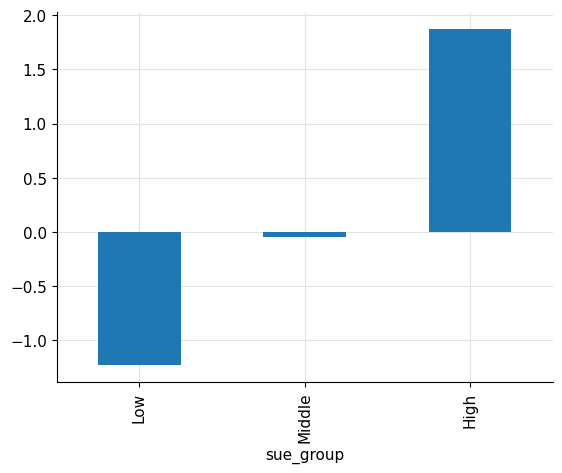

In [219]:
results_pct["mean_car"].plot(kind="bar")

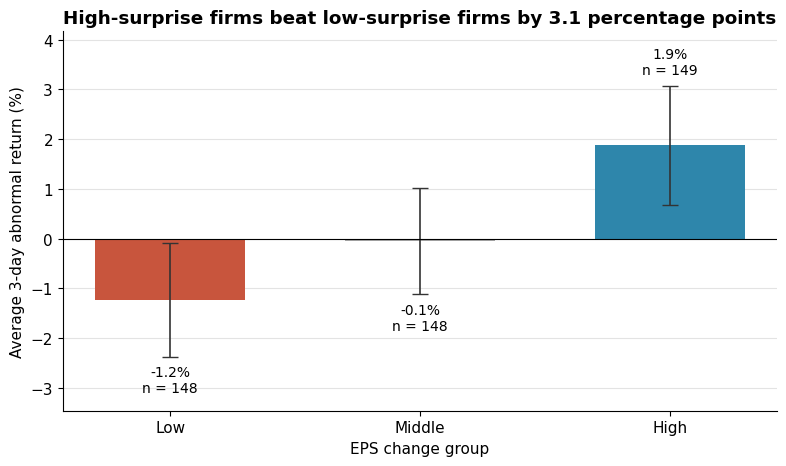

In [220]:
# ===== 2c. Figure 1, made for a client =====
LABELS = ["Low", "Middle", "High"]

plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
#sns.set_theme(style="whitegrid", font_scale=1.1, rc={"axes.grid.axis": "y"})   # 1. theme (once per notebook), horizontal lines only

COLORS = {"Low": "#C8553D", "Middle": "#A9A9A9", "High": "#2E86AB"}    # 2. colors with a meaning

mean = results["mean_car"] * 100
ci   = results["ci95"] * 100
spread = mean["High"] - mean["Low"]
word = "beat" if spread > 0 else "trail"
title = f"High-surprise firms {word} low-surprise firms by {abs(spread):.1f} percentage points"   # 5. the finding

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(LABELS, mean, yerr=ci, capsize=6, width=0.6,                  # 3. error bars = 95% CI
       color=[COLORS[g] for g in LABELS], error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
for i, g in enumerate(LABELS):                                        # 4. value and n on each bar
    top = mean[g] + ci[g] if mean[g] >= 0 else mean[g] - ci[g]
    ax.annotate(f"{mean[g]:.1f}%\nn = {results.loc[g, 'count']}", (i, top),
                xytext=(0, 6 if mean[g] >= 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if mean[g] >= 0 else "top", fontsize=10)
ax.axhline(0, color="black", linewidth=0.8)                           # 6. line at 0
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("EPS change group")
ax.set_ylabel("Average 3-day abnormal return (%)")
ax.margins(y=0.2)
#sns.despine(left=True)                                                # 6. no box
plt.tight_layout()
fig.savefig("figure1_groups.png", dpi=200)                            # for your slides
plt.show()

In [221]:
# ===== 3. Welch t-test: High vs Low =====
high = final_cleaned.loc[final_cleaned["sue_group"] == "High", "car"]
low  = final_cleaned.loc[final_cleaned["sue_group"] == "Low",  "car"]

t, p = stats.ttest_ind(high, low, equal_var=False)

gap = (high.mean() - low.mean()) * 100
print(f"High - Low = {gap:.2f} percentage points | t = {t:.2f} | p = {p:.4f}")

High - Low = 3.10 percentage points | t = 3.67 | p = 0.0003


In [222]:
# ===== 4a. Look at the extremes, then winsorize the return at 1% and 99% =====
print(final_cleaned[["sue", "car"]].describe().round(3))

lo, hi = final_cleaned["car"].quantile([0.01, 0.99])
final_cleaned["car_w"] = final_cleaned["car"].clip(lo, hi)     # clip = pull values outside [lo, hi] to the edge
print(f"\nrows changed by winsorizing: {(final_cleaned['car'] != final_cleaned['car_w']).sum()} of {len(final_cleaned)}")

           sue      car
count  445.000  445.000
mean     0.003    0.002
std      0.055    0.072
min     -0.243   -0.302
25%     -0.003   -0.038
50%      0.001    0.000
75%      0.007    0.041
max      0.673    0.262

rows changed by winsorizing: 10 of 445


In [223]:
# ===== 4b. Regression: original and winsorized =====
model   = smf.ols("car ~ sue", data=final_cleaned).fit()
model_w = smf.ols("car_w ~ sue", data=final_cleaned).fit()

print(model.summary())      # full results table, original
print(model_w.summary())    # full results table, winsorized

results = pd.DataFrame({
    "b (slope)":    [model.params["sue"],  model_w.params["sue"]],
    "p-value of b": [model.pvalues["sue"], model_w.pvalues["sue"]],
    "R-squared":    [model.rsquared,           model_w.rsquared],
    "n":            [int(model.nobs),          int(model_w.nobs)],
}, index=["original", "winsorized 1%/99%"]).round(4)
results

                            OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.232
Date:                Mon, 23 Nov 2026   Prob (F-statistic):              0.268
Time:                        16:07:52   Log-Likelihood:                 542.81
No. Observations:                 445   AIC:                            -1082.
Df Residuals:                     443   BIC:                            -1073.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0018      0.003      0.529      0.5

,b (slope),p-value of b,R-squared,n
original,0.0688,0.2677,0.0028,445
winsorized 1%/99%,0.0765,0.2039,0.0036,445


In [230]:
final_cleaned["fyearq"] = final_cleaned["fyearq"].astype(int)           # nullable Int64 -> plain int
final_cleaned["loss"]  = (final_cleaned["epspxq"] < 0).astype(int)     # 1 = loss firm
lo, hi = final_cleaned["car"].quantile([0.01, 0.99])
final_cleaned["car_w"] = final_cleaned["car"].clip(lo, hi)

cl = dict(cov_type="cluster", cov_kwds={"groups": final_cleaned["gvkey"]})

m1 = smf.ols("car_w ~ sue", data=final_cleaned).fit(**cl)
m2 = smf.ols("car_w ~ sue + C(fyearq)", data=final_cleaned).fit(**cl)
m3 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=final_cleaned).fit(**cl)

summary_col([m1, m2, m3], stars=True,
            model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
            regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) base,(2) year FE,(3) year FE + loss
sue,0.0765,0.0732,0.2636**
,(0.0842),(0.0861),(0.1125)
loss,,,-0.0083
,,,(0.0074)
sue:loss,,,-0.2729**
,,,(0.1124)
R-squared,0.0036,0.0149,0.0263
R-squared Adj.,0.0014,0.0014,0.0084
R2,0.004,0.015,0.026
n,445,445,445


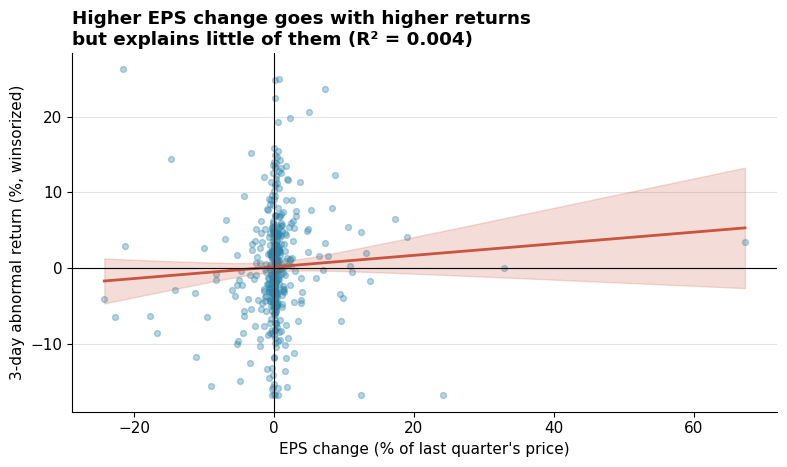

In [225]:
# ===== 4c. Figure 2: every company-year and the regression line =====
b  = model_w.params["sue"]
r2 = model_w.rsquared
title = (f"Higher EPS change goes with {'higher' if b > 0 else 'lower'} returns\n"
         f"but explains little of them (R² = {r2:.3f})")

# the regression line and its 95% band, from the fitted model
grid = pd.DataFrame({"sue": np.linspace(final_cleaned["sue"].min(), final_cleaned["sue"].max(), 100)})
pred = model_w.get_prediction(grid).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(final_cleaned["sue"] * 100, final_cleaned["car_w"] * 100,
           s=18, alpha=0.35, color="#2E86AB")                                   # every company-year
ax.fill_between(grid["sue"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100,
                color="#C8553D", alpha=0.2)                                     # 95% band
ax.plot(grid["sue"] * 100, pred["mean"] * 100, color="#C8553D", linewidth=2)  # regression line
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("EPS change (% of last quarter's price)")
ax.set_ylabel("3-day abnormal return (%, winsorized)")
ax.spines[["top", "right"]].set_visible(False)                                  # no box
plt.tight_layout()
fig.savefig("figure2_regression.png", dpi=200)
plt.show()

In [226]:
# ===== 5a. The class =====
class Industry:
    """One industry: build its table, then group, test, and regress."""

    def __init__(self, sic, name,drop_top5=False):
        self.sic = sic              # attributes: data that belongs to this object
        self.name = name
        self.events = None          # filled by build()
        self.drop_top5 = drop_top5

    # ---------- Part 1: build the table (the same code as Part 1) ----------
    def build(self):
        # 1. Link file
        link = link_all[link_all["sic2"] == self.sic].reset_index(drop=True)
        gv = "'" + "','".join(link["gvkey"].unique()) + "'"

        # 2. Compustat quarterly
        fa = conn.raw_sql(f"""
            select gvkey, datadate, fyearq, epspxq, prccq, rdq, fqtr
            from comp.fundq
            where gvkey in ({gv})
              and datadate between '{PULL_START}' and '{FY_END}'
              and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
        """, date_cols=["datadate"])
        fa["epspxq"] = fa["epspxq"].astype("float64")
        fa["prccq"] = fa["prccq"].astype("float64")
        fa["fyearq"] = fa["fyearq"].astype(int)
        fa["fqtr"] = fa["fqtr"].astype(int)

        # 3. Merge link &  SUE
        panel = fa.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey")
        valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
        panel = panel[valid].drop_duplicates(["gvkey", "datadate"]).drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

        q = panel.copy()
        q["qnum"] = q["fyearq"] * 4 + q["fqtr"]

        eps4 = q[["gvkey", "qnum", "epspxq"]].copy()
        eps4["qnum"] = eps4["qnum"] + 4
        eps4 = eps4.rename(columns={"epspxq": "eps_4q_ago"})

        prc1 = q[["gvkey", "qnum", "prccq"]].copy()
        prc1["qnum"] = prc1["qnum"] + 1
        prc1 = prc1.rename(columns={"prccq": "prc_1q_ago"})

        q = q.merge(eps4, on=["gvkey", "qnum"], how="left").merge(prc1, on=["gvkey", "qnum"], how="left")
        q["sue"] = (q["epspxq"] - q["eps_4q_ago"]) / q["prc_1q_ago"]

        # 1 to 5 Rules
        d = q[q["rdq"].notna()]
        d = d[(d["rdq"] >= FY_START) & (d["rdq"] <= FY_END)]
        d = d[d["sue"].notna() & d["epspxq"].notna() & d["eps_4q_ago"].notna() & d["prc_1q_ago"].notna()]
        d = d[d["prc_1q_ago"] >= MIN_PRC]
        d = d[d["sue"].abs() <= MAX_CHG].reset_index(drop=True)

        # 4. CRSP daily returns y CAR (-1, 0, +1)
        permnos = ",".join(d["permno"].astype(str).unique())
        stock = conn.raw_sql(f"""
            select permno, date, ret from crsp.dsf
            where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'
        """, date_cols=["date"])
        stock["permno"] = stock["permno"].astype(int)
        stock["ret"] = stock["ret"].astype("float64")
        stock = stock.merge(mkt[["date", "vwretd", "tday"]], on="date", how="left")
        stock["ar"] = stock["ret"] - stock["vwretd"]

        d["event_id"] = d.index
        pairs = d[["event_id", "rdq"]].merge(mkt[["date", "tday"]], how="cross")
        pairs = pairs[pairs["date"] >= pairs["rdq"]]
        day0 = pairs.groupby("event_id")["tday"].min().reset_index().rename(columns={"tday": "day0"})
        d = d.merge(day0, on="event_id", how="left")

        offsets = pd.DataFrame({"offset": [-1, 0, 1]})
        window = d[["event_id", "permno", "day0"]].merge(offsets, how="cross")
        window["tday"] = window["day0"] + window["offset"]
        window = window.merge(stock[["permno", "tday", "ar"]], on=["permno", "tday"], how="left")

        car = window.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index().rename(columns={"sum": "car", "count": "days_found"})
        d = d.merge(car, on="event_id", how="left")
        final_df = d[d["days_found"] == 3].reset_index(drop=True)

        # Drop top 5 largest absolute CAR events
        if self.drop_top5:
            top5_idx = final_df["car"].abs().nlargest(5).index
            final_df = final_df.drop(top5_idx).reset_index(drop=True)
            
        # Groups & Winsorizing
        final_df["sue_group"] = pd.qcut(final_df["sue"].rank(method="first"), 3, labels=LABELS)
        lo, hi = final_df["car"].quantile([0.01, 0.99])
        final_df["car_w"] = final_df["car"].clip(lo, hi)

        self.events = final_df
        print(f"{self.name} (SIC {self.sic}): {len(final_df)} events, {final_df['gvkey'].nunique()} companies")
        return self

    def group_table(self):
        t = self.events.groupby("sue_group", observed=True)["car_w"].agg(n="count", mean="mean", sd="std")
        t["ci95"] = 1.96 * t["sd"] / np.sqrt(t["n"])
        return t

    def ttest(self):
        high = self.events.loc[self.events["sue_group"] == "High", "car_w"]
        low = self.events.loc[self.events["sue_group"] == "Low", "car_w"]
        t, p = stats.ttest_ind(high, low, equal_var=False)
        return {"High - Low (pp)": (high.mean() - low.mean()) * 100, "t": t, "p (t-test)": p}

    def regression(self):
        m = smf.ols("car_w ~ sue", data=self.events).fit()
        return {"b": m.params["sue"], "p (b)": m.pvalues["sue"], "R2": m.rsquared}

    def summary(self):
        row = {
            "industry": self.name,
            "SIC": self.sic,
            "n": len(self.events),
            "companies": self.events["gvkey"].nunique()
        }
        row.update(self.ttest())
        row.update(self.regression())
        return row

In [227]:
mine = Industry("58", "Eating & Drinking Places",drop_top5=True).build()
peer = Industry("28", "Chemicals & Pharma",drop_top5=True).build()

compare_df = pd.DataFrame([mine.summary(), peer.summary()]).set_index("industry")
display(compare_df.round(4))

Eating & Drinking Places (SIC 58): 445 events, 34 companies
Chemicals & Pharma (SIC 28): 2574 events, 219 companies


,SIC,n,companies,High - Low (pp),t,p (t-test),b,p (b),R2
industry,,,,,,,,,
Eating & Drinking Places,58,445,34,3.0189,3.7063,0.0003,0.0765,0.2039,0.0036
Chemicals & Pharma,28,2574,219,2.8497,6.4710,0.0000,0.0947,0.0001,0.0058


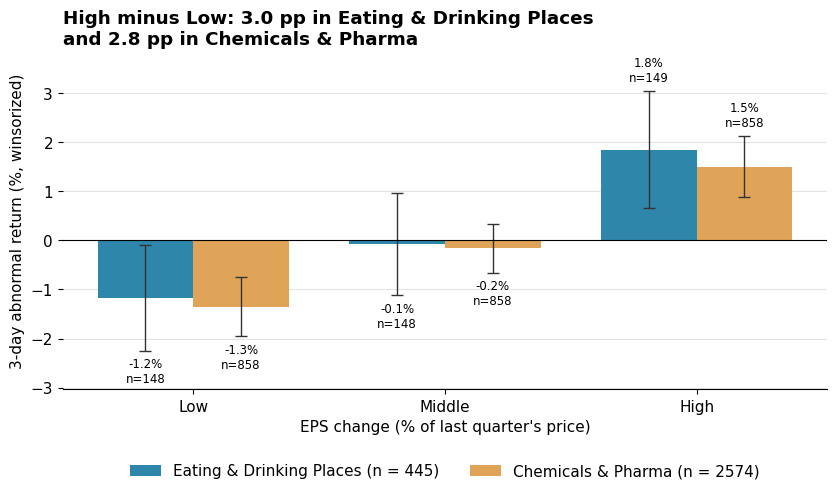

In [228]:
# ===== 5d. Figure 3: my industry vs the peer industry =====
def plot_compare(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    x = np.arange(len(LABELS))
    width = 0.38
    for j, ind in enumerate(industries):
        t = ind.group_table()
        pos = x + (j - 0.5) * width
        mean = t["mean"] * 100
        ci = t["ci95"] * 100
        
        ax.bar(x + (j - 0.5) * width, t["mean"] * 100, width, yerr=t["ci95"] * 100, capsize=4,
               color=colors[j], label=f"{ind.name} (n = {len(ind.events)})",
               error_kw={"elinewidth": 1, "ecolor": "#333333"})
        for i, g in enumerate(LABELS):
            m_val = mean.loc[g]
            c_val = ci.loc[g]
            n_val = int(t.loc[g, "n"])
            top = m_val + c_val if m_val >= 0 else m_val - c_val
            
            ax.annotate(f"{m_val:.1f}%\nn={n_val}", (pos[i], top),
                        xytext=(0, 5 if m_val >= 0 else -5),
                        textcoords="offset points",
                        ha="center", va="bottom" if m_val >= 0 else "top",
                        fontsize=8.5)
            
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, LABELS)
    gaps = [ind.ttest()["High - Low (pp)"] for ind in industries]
    ax.set_title(f"High minus Low: {gaps[0]:.1f} pp in {industries[0].name}\n"
                 f"and {gaps[1]:.1f} pp in {industries[1].name}", loc="left", fontweight="bold")
    ax.set_xlabel("EPS change (% of last quarter's price)")
    ax.set_ylabel("3-day abnormal return (%, winsorized)")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))   # legend under the chart
    ax.margins(y=0.15)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

plot_compare([mine, peer], colors=["#2E86AB", "#E0A458"], file_name="figure3_peer.png")

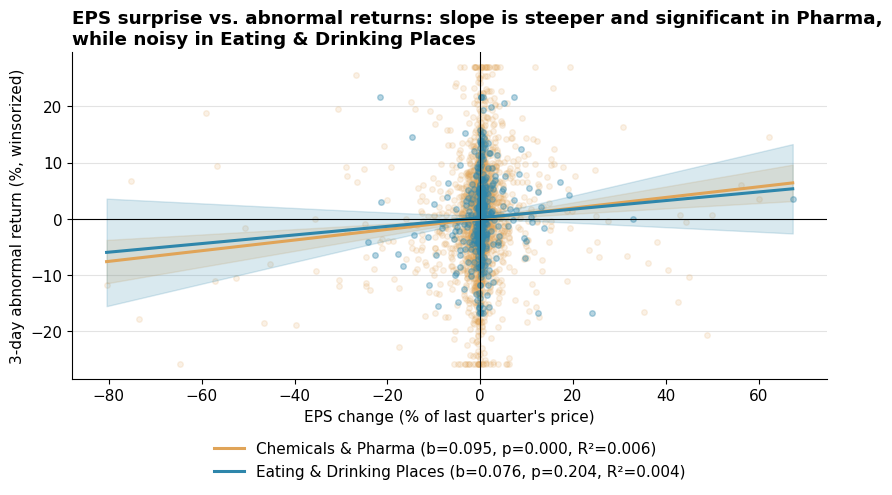

In [229]:
# ===== 5e. Figure 4: Regression comparison (my industry vs peer industry) =====
def plot_compare_reg(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    
    # Common x-axis range for both regression lines (approx. -80% to +65%)
    sue_min = min(ind.events["sue"].min() for ind in industries)
    sue_max = max(ind.events["sue"].max() for ind in industries)
    grid = pd.DataFrame({"sue": np.linspace(sue_min, sue_max, 100)})

    # Plot the larger peer industry first in the background so it doesn't cover the smaller one
    for j in reversed(range(len(industries))):
        ind = industries[j]
        color = colors[j]
        
        # Fit the winsorized OLS model for the industry
        m = smf.ols("car_w ~ sue", data=ind.events).fit()
        pred = m.get_prediction(grid).summary_frame(alpha=0.05)
        
        b = m.params["sue"]
        pval = m.pvalues["sue"]
        r2 = m.rsquared
        
        # 1. Individual company-quarter scatter points (more transparent for the larger industry)
        alpha_pts = 0.35 if j == 0 else 0.15
        ax.scatter(ind.events["sue"] * 100, ind.events["car_w"] * 100,
                   s=16, alpha=alpha_pts, color=color)
        
        # 2. 95% confidence band
        ax.fill_between(grid["sue"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100,
                        color=color, alpha=0.18)
        
        # 3. Regression line with key statistics in the legend
        label_txt = f"{ind.name} (b={b:.3f}, p={pval:.3f}, R²={r2:.3f})"
        ax.plot(grid["sue"] * 100, pred["mean"] * 100, color=color, linewidth=2.2, label=label_txt)

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    
    ax.set_title("EPS surprise vs. abnormal returns: slope is steeper and significant in Pharma,\n"
                 "while noisy in Eating & Drinking Places", loc="left", fontweight="bold")
    ax.set_xlabel("EPS change (% of last quarter's price)")
    ax.set_ylabel("3-day abnormal return (%, winsorized)")
    
    # Place legend below the chart, matching Figure 3
    ax.legend(frameon=False, ncol=1, loc="upper center", bbox_to_anchor=(0.5, -0.15))
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(file_name, dpi=200, bbox_inches="tight")
    plt.show()

plot_compare_reg([mine, peer], colors=["#2E86AB", "#E0A458"], file_name="figure4_compare_reg.png")